# Hobart temperature extremes under SSP3-7.0

How do hot days and cold nights in Hobart change this century, and how much can one regional model be trusted to say so?

**Data** (fetched by `scripts/fetch_hobart.py`, one BARPA-R grid cell over Hobart):

* **AGCD** gridded observations, 1985–2014: the reference.
* **BARPA-R driven by ERA5**, 1985–2014: shows the regional model's own error when its boundaries are fed observed weather.
* **BARPA-R driven by ACCESS-CM2** (r4i1p1f1), historical 1985–2014 and SSP3-7.0 2015–2100: the projection.

**Approach.** Change is always measured within one model chain (ACCESS-CM2 future against ACCESS-CM2 historical), so differences between driving models don't show up as climate change. Windows are 30 years each: 1985–2014 baseline, 2041–2070 and 2071–2100.

* **Frequency:** days per year above the baseline 95th percentile of daily maximum (hot days) and below the baseline 5th percentile of daily minimum (cold nights), thresholds held fixed.
* **Magnitude:** a stationary GEV fitted to each window's annual extremes, giving the 1-in-50-year hottest day and coldest night with a bootstrap 90% interval.

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats

DATA = Path("../data")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

BASELINE = "1985–2014"
WINDOWS = {BASELINE: slice("1985", "2014"), "2041–2070": slice("2041", "2070"), "2071–2100": slice("2071", "2100")}
RETURN_PERIOD = 50  # years

obs = xr.open_dataset(DATA / "hobart_agcd_1985-2014.nc")
era5_run = xr.open_dataset(DATA / "hobart_barpa-r_era5_evaluation_1985-2014.nc")
model = xr.concat(
    [xr.open_dataset(DATA / "hobart_barpa-r_access-cm2_historical_1985-2014.nc"),
     xr.open_dataset(DATA / "hobart_barpa-r_access-cm2_ssp370_2015-2100.nc")],
    dim="time",
)

a = model.attrs
print(f"BARPA-R cell {a['cell_lat']:.3f}, {a['cell_lon']:.3f} ({a['cell_land_fraction_percent']:.0f}% land), "
      f"nearest mostly-land cell to Hobart ({a['site_lat']}, {a['site_lon']})")
print(f"Units: {model.tasmax.units}; model days {model.sizes['time']}, "
      f"{str(model.time.values[0])[:10]} to {str(model.time.values[-1])[:10]}")

BARPA-R cell -42.915, 147.363 (58% land), nearest mostly-land cell to Hobart (-42.88, 147.32)
Units: degC; model days 42368, 1985-01-01 to 2100-12-31


### Where the data come from

Hobart and the BARPA-R grid cell used for every model series. The AGCD observations are averaged over the land inside the same cell, so model and observations describe the same area.

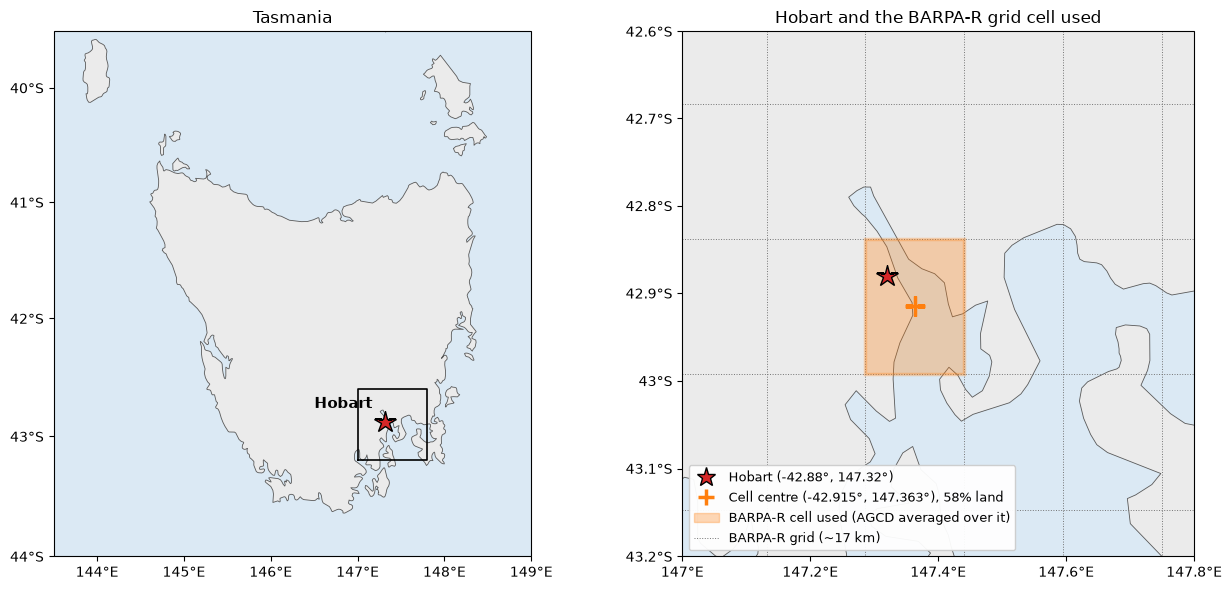

In [2]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

CELL_SIZE = 0.1545  # BARPA-R AUS-15 grid spacing, degrees (about 17 km)
cell_lat, cell_lon = a["cell_lat"], a["cell_lon"]
site_lat, site_lon = a["site_lat"], a["site_lon"]
geo = ccrs.PlateCarree()
zoom = [147.0, 147.8, -43.2, -42.6]  # lon min, lon max, lat min, lat max

fig, (ax_tas, ax_zoom) = plt.subplots(1, 2, figsize=(13, 6), subplot_kw={"projection": ccrs.Mercator()})
land = cfeature.NaturalEarthFeature("physical", "land", "10m")
extents_and_ticks = [
    (ax_tas, [143.5, 149.0, -44.0, -39.5], np.arange(144, 150, 1.0), np.arange(-44, -39, 1.0)),
    (ax_zoom, zoom, np.arange(147.0, 147.85, 0.2), np.arange(-43.2, -42.55, 0.1)),
]
for ax, extent, xticks, yticks in extents_and_ticks:
    ax.set_extent(extent, crs=geo)
    ax.set_facecolor("#dbe9f4")
    ax.add_feature(land, facecolor="0.92", edgecolor="0.35", linewidth=0.6)
    ax.plot(site_lon, site_lat, "*", color="tab:red", ms=16, mec="black", transform=geo, zorder=5)
    # Axis ticks rather than gridliner labels, which break tight_layout.
    ax.set_xticks(np.round(xticks, 2), crs=geo)
    ax.set_yticks(np.round(yticks, 2), crs=geo)
    ax.xaxis.set_major_formatter(LongitudeFormatter())
    ax.yaxis.set_major_formatter(LatitudeFormatter())

ax_tas.plot([zoom[0], zoom[1], zoom[1], zoom[0], zoom[0]], [zoom[2], zoom[2], zoom[3], zoom[3], zoom[2]],
            color="black", lw=1.2, transform=geo)
ax_tas.text(site_lon - 0.15, site_lat + 0.12, "Hobart", transform=geo, fontsize=11, weight="bold", ha="right")
ax_tas.set_title("Tasmania")

edges = (np.arange(-4, 5) + 0.5) * CELL_SIZE
for lat in cell_lat + edges:  # lines run past the frame and are clipped to it
    ax_zoom.plot([zoom[0] - 1, zoom[1] + 1], [lat, lat], color="0.45", lw=0.7, ls=":", transform=geo)
for lon in cell_lon + edges:
    ax_zoom.plot([lon, lon], [zoom[2] - 1, zoom[3] + 1], color="0.45", lw=0.7, ls=":", transform=geo)
ax_zoom.set_extent(zoom, crs=geo)  # plotting past the frame can widen the view, so reset it
ax_zoom.add_patch(Rectangle((cell_lon - CELL_SIZE / 2, cell_lat - CELL_SIZE / 2), CELL_SIZE, CELL_SIZE,
                            fc="tab:orange", alpha=0.3, ec="tab:orange", lw=2.5, transform=geo, zorder=4))
ax_zoom.plot(cell_lon, cell_lat, "+", color="tab:orange", ms=14, mew=2.5, transform=geo, zorder=5)
ax_zoom.set_title("Hobart and the BARPA-R grid cell used")
ax_zoom.legend(handles=[
    Line2D([], [], marker="*", color="tab:red", mec="black", ms=14, ls="",
           label=f"Hobart ({site_lat}°, {site_lon}°)"),
    Line2D([], [], marker="+", color="tab:orange", mew=2.5, ms=12, ls="",
           label=f"Cell centre ({cell_lat:.3f}°, {cell_lon:.3f}°), {a['cell_land_fraction_percent']:.0f}% land"),
    Rectangle((0, 0), 1, 1, fc="tab:orange", alpha=0.3, ec="tab:orange", label="BARPA-R cell used (AGCD averaged over it)"),
    Line2D([], [], color="0.45", lw=0.7, ls=":", label="BARPA-R grid (~17 km)"),
], loc="lower left", fontsize=9, framealpha=0.95)

fig.tight_layout()
fig.savefig(FIGURES / "00_location_map.png", dpi=150)
plt.show()

### Extreme-value helpers

Hot extremes use the annual maximum of daily maximum temperature. Cold extremes use the annual minimum of daily minimum temperature, negated so the same GEV (a distribution for maxima) applies, then negated back.

scipy's `genextreme` shape `c` has the opposite sign to the usual climate convention (`c > 0` means a bounded upper tail). The bootstrap resamples years, so its interval covers sampling uncertainty only, not model or scenario uncertainty.

In [3]:
EXTREMES = {
    # name: (variable, annual reducer, sign that turns it into a maximum)
    "hottest day": ("tasmax", "max", 1),
    "coldest night": ("tasmin", "min", -1),
}


def annual_extremes(ds, name, period):
    variable, how, _ = EXTREMES[name]
    yearly = getattr(ds[variable].sel(time=period).groupby("time.year"), how)()
    return yearly.values


def return_level(sample, sign, period=RETURN_PERIOD):
    c, loc, scale = stats.genextreme.fit(sign * sample)
    return sign * stats.genextreme.isf(1 / period, c, loc=loc, scale=scale)


def return_level_ci(sample, sign, n_boot=500, ci=0.90, seed=0):
    rng = np.random.default_rng(seed)
    draws = [return_level(rng.choice(sample, sample.size, replace=True), sign) for _ in range(n_boot)]
    lower, upper = np.quantile(draws, [(1 - ci) / 2, (1 + ci) / 2])
    return return_level(sample, sign), lower, upper


def return_period_of(level, sample, sign):
    # Average years between events at least as extreme as `level`.
    c, loc, scale = stats.genextreme.fit(sign * sample)
    with np.errstate(divide="ignore"):
        return 1 / stats.genextreme.sf(sign * level, c, loc=loc, scale=scale)

## 1. How good is BARPA-R at Hobart?

Every statistic below is for 1985–2014. Bias is simulation minus observation.

In [4]:
def summary(ds):
    period = WINDOWS[BASELINE]
    tasmax, tasmin = ds.tasmax.sel(time=period), ds.tasmin.sel(time=period)
    return {
        "Mean daily max": float(tasmax.mean()),
        "Mean daily min": float(tasmin.mean()),
        "95th pct daily max": float(tasmax.quantile(0.95)),
        "5th pct daily min": float(tasmin.quantile(0.05)),
        "Mean annual hottest day": annual_extremes(ds, "hottest day", period).mean(),
        "Mean annual coldest night": annual_extremes(ds, "coldest night", period).mean(),
    }


evaluation = pd.DataFrame({
    "AGCD (obs)": summary(obs),
    "BARPA-R / ERA5": summary(era5_run),
    "BARPA-R / ACCESS-CM2": summary(model),
})
evaluation["Bias, ERA5 run"] = evaluation["BARPA-R / ERA5"] - evaluation["AGCD (obs)"]
evaluation["Bias, ACCESS-CM2 run"] = evaluation["BARPA-R / ACCESS-CM2"] - evaluation["AGCD (obs)"]
evaluation.round(1)

,AGCD (obs),BARPA-R / ERA5,BARPA-R / ACCESS-CM2,"Bias, ERA5 run","Bias, ACCESS-CM2 run"
Mean daily max,17.1,15.7,16.4,-1.4,-0.7
Mean daily min,8.0,7.4,7.8,-0.6,-0.2
95th pct daily max,25.9,25.1,25.7,-0.7,-0.2
5th pct daily min,2.4,1.7,1.9,-0.6,-0.5
Mean annual hottest day,34.9,34.5,35.8,-0.4,1.0
Mean annual coldest night,-0.1,-1.2,-1.1,-1.1,-1.0


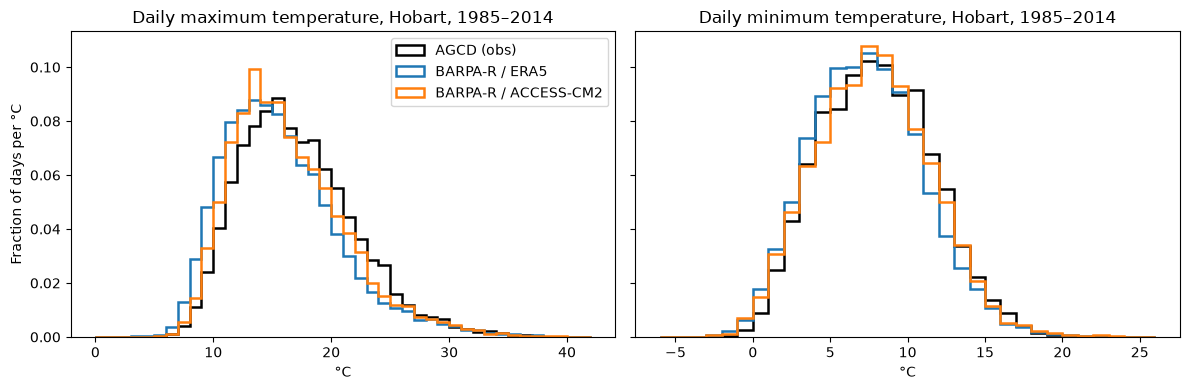

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
period = WINDOWS[BASELINE]
panels = [("tasmax", "Daily maximum", np.arange(0, 43, 1)), ("tasmin", "Daily minimum", np.arange(-6, 27, 1))]
for ax, (variable, title, bins) in zip(axes, panels):
    for ds, label, colour in [(obs, "AGCD (obs)", "black"), (era5_run, "BARPA-R / ERA5", "tab:blue"),
                              (model, "BARPA-R / ACCESS-CM2", "tab:orange")]:
        ax.hist(ds[variable].sel(time=period), bins=bins, density=True, histtype="step", lw=1.8,
                color=colour, label=label)
    ax.set_title(f"{title} temperature, Hobart, 1985–2014")
    ax.set_xlabel("°C")
axes[0].set_ylabel("Fraction of days per °C")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIGURES / "01_evaluation.png", dpi=150)
plt.show()

## 2. Hot days and cold nights per year

Thresholds come from the ACCESS-CM2 run's own 1985–2014 climate, so a biased model is compared with itself. By construction each threshold is crossed on about 18 days a year in the baseline.

In [6]:
baseline = model.sel(time=WINDOWS[BASELINE])
hot_threshold = float(baseline.tasmax.quantile(0.95))
cold_threshold = float(baseline.tasmin.quantile(0.05))
print(f"Hot day: daily max above {hot_threshold:.1f} °C; cold night: daily min below {cold_threshold:.1f} °C "
      f"(ACCESS-CM2 run, 1985–2014)")

counts = pd.DataFrame({
    "hot days": (model.tasmax > hot_threshold).groupby("time.year").sum().to_series(),
    "cold nights": (model.tasmin < cold_threshold).groupby("time.year").sum().to_series(),
})
counts = counts.loc[1985:2100]

frequency = pd.DataFrame({
    window: counts.loc[int(period.start):int(period.stop)].mean() for window, period in WINDOWS.items()
}).round(1)
frequency.index = ["Hot days per year", "Cold nights per year"]
frequency

Hot day: daily max above 25.7 °C; cold night: daily min below 1.9 °C (ACCESS-CM2 run, 1985–2014)


,1985–2014,2041–2070,2071–2100
Hot days per year,18.3,32.8,49.3
Cold nights per year,18.2,3.6,0.6


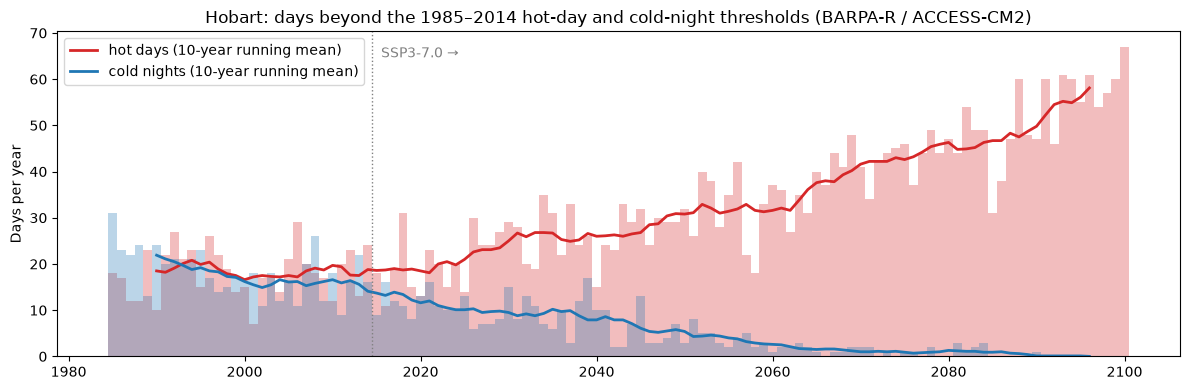

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
for column, colour in [("hot days", "tab:red"), ("cold nights", "tab:blue")]:
    ax.bar(counts.index, counts[column], color=colour, alpha=0.3, width=1.0)
    ax.plot(counts.index, counts[column].rolling(10, center=True).mean(), color=colour, lw=2,
            label=f"{column} (10-year running mean)")
ax.axvline(2014.5, color="grey", ls=":", lw=1)
ax.text(2015.5, ax.get_ylim()[1] * 0.92, "SSP3-7.0 →", color="grey")
ax.set_ylabel("Days per year")
ax.set_title("Hobart: days beyond the 1985–2014 hot-day and cold-night thresholds (BARPA-R / ACCESS-CM2)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "02_hot_days_cold_nights.png", dpi=150)
plt.show()

## 3. The 1-in-50-year hottest day and coldest night

Each 30-year window gets its own stationary GEV. The last column says how often the baseline 1-in-50-year event happens in each future window. `inf` means the event lies beyond the bound of the fitted future GEV: under that fit it no longer happens at all, which is best read as "very rare" given 30 years of data.

In [8]:
rows = []
for name, (_, _, sign) in EXTREMES.items():
    base_sample = annual_extremes(model, name, WINDOWS[BASELINE])
    base_level = return_level(base_sample, sign)
    for window, period in WINDOWS.items():
        sample = annual_extremes(model, name, period)
        level, lower, upper = return_level_ci(sample, sign)
        rows.append({
            "extreme": name, "window": window, "50-yr level (°C)": level,
            "90% CI low": lower, "90% CI high": upper, "change (°C)": level - base_level,
            "baseline 50-yr event recurs every (yr)": return_period_of(base_level, sample, sign),
        })
return_levels = pd.DataFrame(rows).set_index(["extreme", "window"])
return_levels.round(1)

50-yr level (°C)  90% CI low  90% CI high  \
extreme       window                                                 
hottest day   1985–2014              39.7        39.2         40.4   
              2041–2070              42.1        41.5         42.4   
              2071–2100              44.4        43.5         45.4   
coldest night 1985–2014              -2.8        -4.1         -2.3   
              2041–2070              -0.8        -1.5         -0.5   
              2071–2100               0.3        -0.2          0.8   

                         change (°C)  baseline 50-yr event recurs every (yr)  
extreme       window                                                          
hottest day   1985–2014          0.0                                    50.0  
              2041–2070          2.4                                     2.9  
              2071–2100          4.7                                     1.6  
coldest night 1985–2014          0.0                                    50.0  
              2041–2070          2.0                                     inf  
              2071–2100          3.0                                     inf

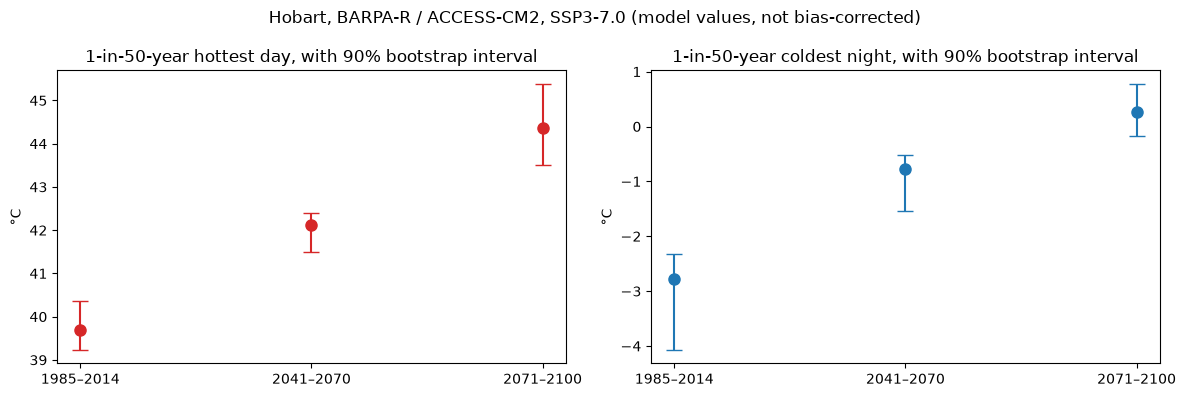

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, colour) in zip(axes, [("hottest day", "tab:red"), ("coldest night", "tab:blue")]):
    table = return_levels.loc[name]
    x = np.arange(len(table))
    ax.errorbar(x, table["50-yr level (°C)"],
                yerr=[table["50-yr level (°C)"] - table["90% CI low"], table["90% CI high"] - table["50-yr level (°C)"]],
                fmt="o", color=colour, capsize=6, ms=8)
    ax.set_xticks(x, table.index)
    ax.set_ylabel("°C")
    ax.set_title(f"1-in-{RETURN_PERIOD}-year {name}, with 90% bootstrap interval")
fig.suptitle("Hobart, BARPA-R / ACCESS-CM2, SSP3-7.0 (model values, not bias-corrected)")
fig.tight_layout()
fig.savefig(FIGURES / "03_return_levels.png", dpi=150)
plt.show()

### Anchoring to observations

The model's absolute values carry its bias (section 1). A simple fix is the delta method: take the 1-in-50-year level fitted to AGCD for 1985–2014 and add the model's *change*. This assumes the bias stays the same as the climate warms. Thirty years of observations make a 50-year level uncertain, as the interval shows.

In [10]:
rows = []
for name, (_, _, sign) in EXTREMES.items():
    observed, lower, upper = return_level_ci(annual_extremes(obs, name, WINDOWS[BASELINE]), sign)
    row = {"extreme": name, f"AGCD {BASELINE}": observed, "AGCD 90% CI": f"{lower:.1f} to {upper:.1f}"}
    for window in list(WINDOWS)[1:]:
        row[window] = observed + return_levels.loc[(name, window), "change (°C)"]
    rows.append(row)
anchored = pd.DataFrame(rows).set_index("extreme")
anchored.round(1)

,AGCD 1985–2014,AGCD 90% CI,2041–2070,2071–2100
extreme,,,,
hottest day,38.5,37.4 to 38.9,41.0,43.2
coldest night,-1.2,-1.5 to -1.0,0.8,1.8


## Limitations

* **One regional model, one driving model, one member, one scenario.** ACCESS-CM2 is one of seven BARPA-R driving models, so this is a single storyline, not a range. A full ensemble would separate model spread from the climate signal.
* **One grid cell.** The 17 km cell includes part of the Derwent estuary and averages over terrain, so it smooths both the coast and kunanyi/Mt Wellington.
* **Stationary GEV within each window.** Warming inside a 30-year window slightly blurs the fit. A covariate-dependent GEV would handle this.
* **Fixed-percentile thresholds over the whole year.** Hot days fall in summer and cold nights in winter. These are statistical thresholds, not health or infrastructure thresholds.
* **Delta method.** It assumes the model's bias at the extremes stays constant. Quantile mapping against AGCD would be the next step.